In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "final"
    / "model_features_20d_provisional.csv"
)

TABLES_DIR = PROJECT_ROOT / "tables"
FIGURES_DIR = PROJECT_ROOT / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

for directory in [TABLES_DIR, FIGURES_DIR, MODELS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["Date"]
)

df = df.sort_values("Date").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())

assert df["Date"].is_unique
assert df["Date"].is_monotonic_increasing

Dataset shape: (3944, 17)
Date range: 2010-03-31 00:00:00 to 2025-12-02 00:00:00


In [2]:
TARGET = "RV_Future_20D"
HORIZON = 20

TEST_START = pd.Timestamp("2023-01-01")
TEST_END = pd.Timestamp("2025-12-31")

test_indices = df.index[
    (df["Date"] >= TEST_START)
    & (df["Date"] <= TEST_END)
].to_numpy()

first_test_idx = test_indices[0]

# Only training labels fully observable before test starts.
training_indices = np.arange(
    0,
    first_test_idx - HORIZON
)

train_df = df.iloc[training_indices].copy()
test_df = df.iloc[test_indices].copy()

print("=" * 60)
print("FINAL OUT-OF-SAMPLE SPLIT")
print("=" * 60)

print("Training observations:", len(train_df))
print("Test observations:", len(test_df))

print("\nTraining period:")
print(
    train_df["Date"].min(),
    "to",
    train_df["Date"].max()
)

print("\nTest period:")
print(
    test_df["Date"].min(),
    "to",
    test_df["Date"].max()
)

assert len(test_df) == 732

assert (
    training_indices[-1] + HORIZON
    < first_test_idx
)

print("\nChronological split verified!")

FINAL OUT-OF-SAMPLE SPLIT
Training observations: 3192
Test observations: 732

Training period:
2010-03-31 00:00:00 to 2022-12-01 00:00:00

Test period:
2023-01-03 00:00:00 to 2025-12-02 00:00:00

Chronological split verified!


In [3]:
MARKET_FEATURES = [
    "Return_Lag1",
    "Absolute_Return",
    "RV_Historical_5D",
    "RV_Historical_10D",
    "RV_Historical_20D",
    "RV_Historical_60D",
    "RV_20D_Lag1"
]

GPR_FEATURES = [
    "GPR_Level",
    "GPR_Change",
    "GPR_MA5",
    "GPR_MA20"
]

TARGET = "RV_Future_20D"

FEATURE_SETS = {
    "Market": MARKET_FEATURES,
    "Market_GPR": MARKET_FEATURES + GPR_FEATURES
}

print("Market features:", len(MARKET_FEATURES))
print("Market + GPR features:", len(FEATURE_SETS["Market_GPR"]))

assert df[
    MARKET_FEATURES + GPR_FEATURES + [TARGET]
].notna().all().all()

Market features: 7
Market + GPR features: 11


In [4]:
def evaluate_predictions(actual, predicted, epsilon=1e-4):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    mae = mean_absolute_error(
        actual,
        predicted
    )

    safe_mape = np.mean(
        np.abs(actual - predicted)
        / np.maximum(np.abs(actual), epsilon)
    ) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "Safe_MAPE": safe_mape
    }

In [5]:
def create_final_models():

    return {
        "Linear Regression": (
            LinearRegression(),
            MARKET_FEATURES
        ),

        "Random Forest": (
            RandomForestRegressor(
                n_estimators=200,
                max_depth=8,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            ),
            MARKET_FEATURES
        ),

        "XGBoost": (
            XGBRegressor(
                n_estimators=300,
                max_depth=3,
                learning_rate=0.03,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1
            ),
            MARKET_FEATURES
        ),

        "XGBoost + GPR (Provisional)": (
            XGBRegressor(
                n_estimators=300,
                max_depth=3,
                learning_rate=0.03,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1
            ),
            MARKET_FEATURES + GPR_FEATURES
        )
    }

In [6]:
from sklearn.base import clone

final_models = create_final_models()

test_predictions = {}
test_metrics = []
trained_models = {}

for model_name, (model, features) in final_models.items():

    print("\n" + "=" * 60)
    print("Training:", model_name)
    print("=" * 60)

    X_train = train_df[features]
    y_train = train_df[TARGET]

    X_test = test_df[features]
    y_test = test_df[TARGET]

    fitted_model = clone(model)

    fitted_model.fit(
        X_train,
        y_train
    )

    predictions = fitted_model.predict(X_test)

    metrics = evaluate_predictions(
        y_test,
        predictions
    )

    test_predictions[model_name] = predictions
    trained_models[model_name] = fitted_model

    test_metrics.append({
        "Model": model_name,
        **metrics
    })

    print(
        f"RMSE: {metrics['RMSE']:.6f} | "
        f"MAE: {metrics['MAE']:.6f} | "
        f"Safe MAPE: {metrics['Safe_MAPE']:.2f}%"
    )

supervised_results = pd.DataFrame(test_metrics)

display(
    supervised_results.sort_values("RMSE").round(6)
)


Training: Linear Regression
RMSE: 0.017902 | MAE: 0.011252 | Safe MAPE: 29.81%

Training: Random Forest
RMSE: 0.019937 | MAE: 0.011745 | Safe MAPE: 29.58%

Training: XGBoost
RMSE: 0.019411 | MAE: 0.011552 | Safe MAPE: 29.54%

Training: XGBoost + GPR (Provisional)
RMSE: 0.020130 | MAE: 0.013150 | Safe MAPE: 35.97%


,Model,RMSE,MAE,Safe_MAPE
0,Linear Regression,0.017902,0.011252,29.809760
2,XGBoost,0.019411,0.011552,29.541793
1,Random Forest,0.019937,0.011745,29.580500
3,XGBoost + GPR (Provisional),0.020130,0.013150,35.965345


In [7]:
persistence_predictions = test_df[
    "RV_Historical_20D"
].to_numpy()

persistence_metrics = evaluate_predictions(
    test_df[TARGET],
    persistence_predictions
)

test_predictions["Persistence"] = persistence_predictions

print("=" * 60)
print("PERSISTENCE TEST RESULTS")
print("=" * 60)

for metric, value in persistence_metrics.items():
    print(f"{metric}: {value:.6f}")

PERSISTENCE TEST RESULTS
RMSE: 0.021363
MAE: 0.012794
Safe_MAPE: 31.104661


In [8]:
print("=" * 60)
print("FINAL TEST PREDICTION CHECK")
print("=" * 60)

for model_name, predictions in test_predictions.items():

    predictions = np.asarray(predictions)

    print(
        f"{model_name}: "
        f"{len(predictions)} predictions"
    )

    assert len(predictions) == len(test_df)

    assert np.isfinite(predictions).all()

print("\nAll predictions aligned successfully!")

FINAL TEST PREDICTION CHECK
Linear Regression: 732 predictions
Random Forest: 732 predictions
XGBoost: 732 predictions
XGBoost + GPR (Provisional): 732 predictions
Persistence: 732 predictions

All predictions aligned successfully!


In [9]:
initial_test_results = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": test_df[TARGET].to_numpy()
})

for model_name, predictions in test_predictions.items():
    initial_test_results[model_name] = predictions

initial_test_results.to_csv(
    TABLES_DIR / "final_test_supervised_predictions.csv",
    index=False
)

print("Saved:", TABLES_DIR / "final_test_supervised_predictions.csv")

Saved: C:\Users\ibrah\RPDA8412 Research Project\tables\final_test_supervised_predictions.csv


In [12]:
from pathlib import Path
import pandas as pd
from arch import arch_model

# Correct dataset location
GARCH_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "final"
    / "daily_volatility_engineered_provisional.csv"
)

print("Dataset location:", GARCH_DATA_PATH)

# Load dataset
garch_df = pd.read_csv(
    GARCH_DATA_PATH,
    parse_dates=["Date"]
)

garch_df = (
    garch_df
    .sort_values("Date")
    .reset_index(drop=True)
)

# Convert log returns to percentages for GARCH
garch_df["Return_Percent"] = (
    garch_df["Log_Return"] * 100
)

print("\nGARCH dataset shape:", garch_df.shape)

print(
    "Available return observations:",
    garch_df["Return_Percent"].notna().sum()
)

print(
    "Date range:",
    garch_df["Date"].min(),
    "to",
    garch_df["Date"].max()
)

print("\nGARCH dataset loaded successfully!")

Dataset location: C:\Users\ibrah\RPDA8412 Research Project\data\final\daily_volatility_engineered_provisional.csv

GARCH dataset shape: (4024, 16)
Available return observations: 4023
Date range: 2010-01-04 00:00:00 to 2025-12-31 00:00:00

GARCH dataset loaded successfully!


In [11]:
from pathlib import Path

print("PROJECT ROOT:", PROJECT_ROOT)
print("PROJECT ROOT EXISTS:", PROJECT_ROOT.exists())

print("\nAVAILABLE CSV FILES:")
print("=" * 60)

for file in PROJECT_ROOT.rglob("*.csv"):
    print(file.relative_to(PROJECT_ROOT))

PROJECT ROOT: C:\Users\ibrah\RPDA8412 Research Project
PROJECT ROOT EXISTS: True

AVAILABLE CSV FILES:
tables\all_models_validation_comparison.csv
tables\baseline_model_comparison.csv
tables\correlation_matrix.csv
tables\descriptive_statistics.csv
tables\final_test_supervised_predictions.csv
tables\garch_model_comparison.csv
tables\garch_validation_predictions.csv
tables\garch_walk_forward_comparison.csv
tables\garch_walk_forward_predictions.csv
tables\gpr_epu_ablation_improvements.csv
tables\gpr_epu_ablation_metrics.csv
tables\gpr_epu_ablation_predictions.csv
tables\linear_regression_validation_metrics.csv
tables\linear_regression_validation_predictions.csv
tables\linear_regression_walk_forward_comparison.csv
tables\lstm_refined_validation_predictions.csv
tables\lstm_reproducibility_summary.csv
tables\lstm_seed_comparison.csv
tables\lstm_validation_predictions.csv
tables\random_forest_baseline_comparison.csv
tables\random_forest_feature_ablation_provisional.csv
tables\random_forest_fe

In [13]:
def expanding_window_garch_test(
    data,
    forecast_dates,
    horizon=20
):

    results = []

    for i, forecast_date in enumerate(forecast_dates):

        historical_returns = (
            data.loc[
                data["Date"] <= forecast_date,
                "Return_Percent"
            ]
            .dropna()
            .to_numpy()
        )

        model = arch_model(
            historical_returns,
            mean="Constant",
            vol="GARCH",
            p=1,
            q=1,
            dist="normal",
            rescale=False
        )

        fitted = model.fit(
            disp="off",
            show_warning=False
        )

        forecast = fitted.forecast(
            horizon=horizon,
            reindex=False
        )

        forecast_variances = (
            forecast.variance.iloc[-1].to_numpy()
        )

        mu = fitted.params["mu"]

        predicted_rv = np.sqrt(
            np.sum(
                forecast_variances + mu**2
            )
        ) / 100

        results.append({
            "Date": forecast_date,
            "Predicted": predicted_rv,
            "Convergence_Flag": fitted.convergence_flag,
            "Alpha": fitted.params["alpha[1]"],
            "Beta": fitted.params["beta[1]"]
        })

        if (i + 1) % 100 == 0:
            print(
                f"Completed {i + 1} / "
                f"{len(forecast_dates)} forecasts"
            )

    return pd.DataFrame(results)

In [14]:
garch_test_predictions = expanding_window_garch_test(
    data=garch_df,
    forecast_dates=test_df["Date"].to_numpy(),
    horizon=20
)

print("\nGARCH forecasting complete!")

print(
    "Total predictions:",
    len(garch_test_predictions)
)

display(garch_test_predictions.head())

Completed 100 / 732 forecasts
Completed 200 / 732 forecasts
Completed 300 / 732 forecasts
Completed 400 / 732 forecasts
Completed 500 / 732 forecasts
Completed 600 / 732 forecasts
Completed 700 / 732 forecasts

GARCH forecasting complete!
Total predictions: 732


,Date,Predicted,Convergence_Flag,Alpha,Beta
0,2023-01-03,0.048327,0,0.180661,0.792698
1,2023-01-04,0.046516,0,0.180690,0.792593
2,2023-01-05,0.048397,0,0.180616,0.792737
3,2023-01-06,0.058325,0,0.180863,0.792900
4,2023-01-09,0.053707,0,0.180514,0.793130


In [15]:
garch_test_results = test_df[
    ["Date", TARGET]
].merge(
    garch_test_predictions,
    on="Date",
    how="left",
    validate="one_to_one"
)

assert len(garch_test_results) == 732

assert (
    garch_test_results["Predicted"]
    .notna()
    .all()
)

garch_metrics = evaluate_predictions(
    garch_test_results[TARGET],
    garch_test_results["Predicted"]
)

print("=" * 60)
print("FINAL GARCH TEST RESULTS")
print("=" * 60)

for metric, value in garch_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nConvergence summary:")

print(
    garch_test_results[
        "Convergence_Flag"
    ].value_counts()
)

test_predictions["GARCH Expanding Window"] = (
    garch_test_results["Predicted"].to_numpy()
)

FINAL GARCH TEST RESULTS
RMSE: 0.019291
MAE: 0.012415
Safe_MAPE: 33.890349

Convergence summary:
Convergence_Flag
0    732
Name: count, dtype: int64


In [16]:
garch_test_results.to_csv(
    TABLES_DIR / "final_test_garch_predictions.csv",
    index=False
)

print("GARCH test results saved successfully!")

GARCH test results saved successfully!


In [17]:
import os
import random
import numpy as np
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dropout, Dense
from tensorflow.keras.optimizers import Adam

SEED = 42
SEQUENCE_LENGTH = 20
LSTM_EPOCHS = 3
LSTM_BATCH_SIZE = 32

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    print("Deterministic operations could not be enabled.")

print("TensorFlow version:", tf.__version__)
print("Random seed:", SEED)

TensorFlow version: 2.22.0-rc0
Random seed: 42


In [18]:
lstm_features = MARKET_FEATURES.copy()

lstm_scaler = StandardScaler()

lstm_scaler.fit(
    train_df[lstm_features]
)

X_all_scaled = lstm_scaler.transform(
    df[lstm_features]
)

y_all = df[TARGET].to_numpy()

print("Scaled feature matrix:", X_all_scaled.shape)
print("Target vector:", y_all.shape)

assert X_all_scaled.shape == (3944, 7)

Scaled feature matrix: (3944, 7)
Target vector: (3944,)


In [19]:
def build_sequences(
    X_scaled,
    y,
    target_indices,
    sequence_length=20
):

    X_sequences = []
    y_sequences = []

    for idx in target_indices:

        start_idx = idx - sequence_length + 1

        if start_idx < 0:
            continue

        sequence = X_scaled[
            start_idx:idx + 1
        ]

        X_sequences.append(sequence)
        y_sequences.append(y[idx])

    return (
        np.asarray(X_sequences),
        np.asarray(y_sequences)
    )


X_train_lstm, y_train_lstm = build_sequences(
    X_all_scaled,
    y_all,
    training_indices,
    SEQUENCE_LENGTH
)

X_test_lstm, y_test_lstm = build_sequences(
    X_all_scaled,
    y_all,
    test_indices,
    SEQUENCE_LENGTH
)

print("LSTM training sequences:", X_train_lstm.shape)
print("LSTM test sequences:", X_test_lstm.shape)

assert X_test_lstm.shape == (732, 20, 7)
assert len(y_test_lstm) == 732

np.testing.assert_allclose(
    y_test_lstm,
    test_df[TARGET].to_numpy()
)

print("\nSequence alignment verified!")

LSTM training sequences: (3173, 20, 7)
LSTM test sequences: (732, 20, 7)

Sequence alignment verified!


In [20]:
def build_final_lstm():

    model = Sequential([
        Input(shape=(20, 7)),

        LSTM(32),

        Dropout(0.20),

        Dense(
            16,
            activation="relu"
        ),

        Dense(
            1,
            activation="softplus"
        )
    ])

    model.compile(
        optimizer=Adam(
            learning_rate=0.001
        ),
        loss="mse"
    )

    return model


final_lstm = build_final_lstm()

final_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,665 (22.13 KB)

 Trainable params: 5,665 (22.13 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
print("=" * 60)
print("TRAINING FINAL LSTM")
print("=" * 60)

history = final_lstm.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=LSTM_EPOCHS,
    batch_size=LSTM_BATCH_SIZE,
    shuffle=False,
    verbose=1
)

print("\nFinal LSTM training complete!")

TRAINING FINAL LSTM
Epoch 1/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.1540
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0094
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0012   

Final LSTM training complete!


In [22]:
lstm_test_predictions = (
    final_lstm.predict(
        X_test_lstm,
        verbose=0
    )
    .flatten()
)

assert len(lstm_test_predictions) == 732
assert np.isfinite(lstm_test_predictions).all()

lstm_metrics = evaluate_predictions(
    y_test_lstm,
    lstm_test_predictions
)

print("=" * 60)
print("FINAL LSTM TEST RESULTS")
print("=" * 60)

for metric, value in lstm_metrics.items():
    print(f"{metric}: {value:.6f}")

test_predictions["LSTM"] = lstm_test_predictions

FINAL LSTM TEST RESULTS
RMSE: 0.022243
MAE: 0.015380
Safe_MAPE: 37.036409


In [23]:
final_lstm.save(
    MODELS_DIR / "lstm_final_test.keras"
)

lstm_results = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": y_test_lstm,
    "LSTM_Predicted": lstm_test_predictions
})

lstm_results.to_csv(
    TABLES_DIR / "final_test_lstm_predictions.csv",
    index=False
)

print("Final LSTM model and predictions saved!")

Final LSTM model and predictions saved!


In [ ]:
# ============================================================
# COMBINE FINAL TEST PREDICTIONS
# ============================================================

import numpy as np
import pandas as pd

expected_models = [
    "Persistence",
    "Linear Regression",
    "Random Forest",
    "XGBoost",
    "XGBoost + GPR (Provisional)",
    "GARCH Expanding Window",
    "LSTM"
]

for model_name in expected_models:

    assert model_name in test_predictions, (
        f"Missing predictions for: {model_name}"
    )

    predictions = np.asarray(
        test_predictions[model_name]
    ).flatten()

    assert len(predictions) == len(test_df)
    assert np.isfinite(predictions).all()

print("All seven models verified!")

final_predictions = pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": test_df[TARGET].to_numpy()
})

for model_name in expected_models:

    final_predictions[model_name] = (
        np.asarray(
            test_predictions[model_name]
        ).flatten()
    )

display(final_predictions.head())

print("\nFinal dataset shape:", final_predictions.shape)

All seven models verified!


,Date,Actual,Persistence,Linear Regression,Random Forest,XGBoost,XGBoost + GPR (Provisional),GARCH Expanding Window,LSTM
0,2023-01-03,0.048572,0.052300,0.047322,0.053448,0.051116,0.046083,0.048327,0.044552
1,2023-01-04,0.050158,0.049655,0.047536,0.053893,0.052973,0.048858,0.046516,0.043516
2,2023-01-05,0.049869,0.048913,0.046756,0.049144,0.044803,0.044886,0.048397,0.045006
3,2023-01-06,0.044887,0.053843,0.058018,0.053493,0.052793,0.050142,0.058325,0.044182
4,2023-01-09,0.046667,0.053324,0.044113,0.049141,0.044597,0.045109,0.053707,0.046816



Final dataset shape: (732, 9)


In [25]:
# ============================================================
#  FINAL MODEL PERFORMANCE
# ============================================================

final_metrics = []

actual = final_predictions["Actual"].to_numpy()

for model_name in expected_models:

    predicted = final_predictions[
        model_name
    ].to_numpy()

    metrics = evaluate_predictions(
        actual,
        predicted
    )

    final_metrics.append({
        "Model": model_name,
        "RMSE": metrics["RMSE"],
        "MAE": metrics["MAE"],
        "Safe_MAPE": metrics["Safe_MAPE"]
    })

final_comparison = pd.DataFrame(
    final_metrics
)

final_comparison = (
    final_comparison
    .sort_values("RMSE")
    .reset_index(drop=True)
)

final_comparison.insert(
    0,
    "Rank",
    range(1, len(final_comparison) + 1)
)

print("=" * 65)
print("FINAL OUT-OF-SAMPLE MODEL COMPARISON")
print("=" * 65)

display(final_comparison.round(6))

FINAL OUT-OF-SAMPLE MODEL COMPARISON


,Rank,Model,RMSE,MAE,Safe_MAPE
0,1,Linear Regression,0.017902,0.011252,29.809760
1,2,GARCH Expanding Window,0.019291,0.012415,33.890349
2,3,XGBoost,0.019411,0.011552,29.541793
3,4,Random Forest,0.019937,0.011745,29.580500
4,5,XGBoost + GPR (Provisional),0.020130,0.013150,35.965345
5,6,Persistence,0.021363,0.012794,31.104661
6,7,LSTM,0.022243,0.015380,37.036409


In [26]:
# ============================================================
# IMPROVEMENT OVER PERSISTENCE
# ============================================================

persistence_rmse = final_comparison.loc[
    final_comparison["Model"] == "Persistence",
    "RMSE"
].iloc[0]

persistence_mae = final_comparison.loc[
    final_comparison["Model"] == "Persistence",
    "MAE"
].iloc[0]

final_comparison[
    "RMSE_Improvement_Percent"
] = (
    (
        persistence_rmse
        - final_comparison["RMSE"]
    )
    / persistence_rmse
) * 100

final_comparison[
    "MAE_Improvement_Percent"
] = (
    (
        persistence_mae
        - final_comparison["MAE"]
    )
    / persistence_mae
) * 100

display(
    final_comparison[
        [
            "Model",
            "RMSE_Improvement_Percent",
            "MAE_Improvement_Percent"
        ]
    ].round(2)
)

,Model,RMSE_Improvement_Percent,MAE_Improvement_Percent
0,Linear Regression,16.20,12.05
1,GARCH Expanding Window,9.70,2.96
2,XGBoost,9.14,9.71
3,Random Forest,6.67,8.19
4,XGBoost + GPR (Provisional),5.77,-2.79
5,Persistence,0.00,0.00
6,LSTM,-4.12,-20.22


In [27]:
final_predictions.to_csv(
    TABLES_DIR / "final_test_all_model_predictions.csv",
    index=False
)

final_comparison.to_csv(
    TABLES_DIR / "final_test_model_comparison.csv",
    index=False
)

print("Files saved successfully!")

print(
    TABLES_DIR / "final_test_all_model_predictions.csv"
)

print(
    TABLES_DIR / "final_test_model_comparison.csv"
)

Files saved successfully!
C:\Users\ibrah\RPDA8412 Research Project\tables\final_test_all_model_predictions.csv
C:\Users\ibrah\RPDA8412 Research Project\tables\final_test_model_comparison.csv


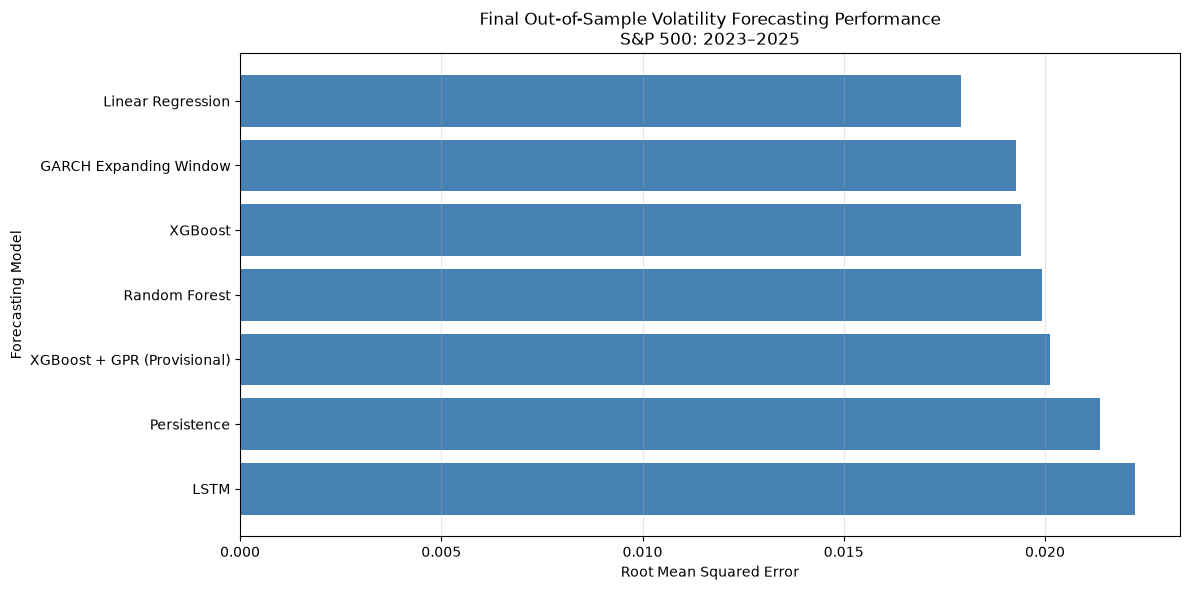

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plot_data = final_comparison.sort_values(
    "RMSE",
    ascending=True
)

plt.barh(
    plot_data["Model"],
    plot_data["RMSE"],
    color="steelblue"
)

plt.gca().invert_yaxis()

plt.xlabel("Root Mean Squared Error")
plt.ylabel("Forecasting Model")

plt.title(
    "Final Out-of-Sample Volatility Forecasting Performance\n"
    "S&P 500: 2023–2025"
)

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

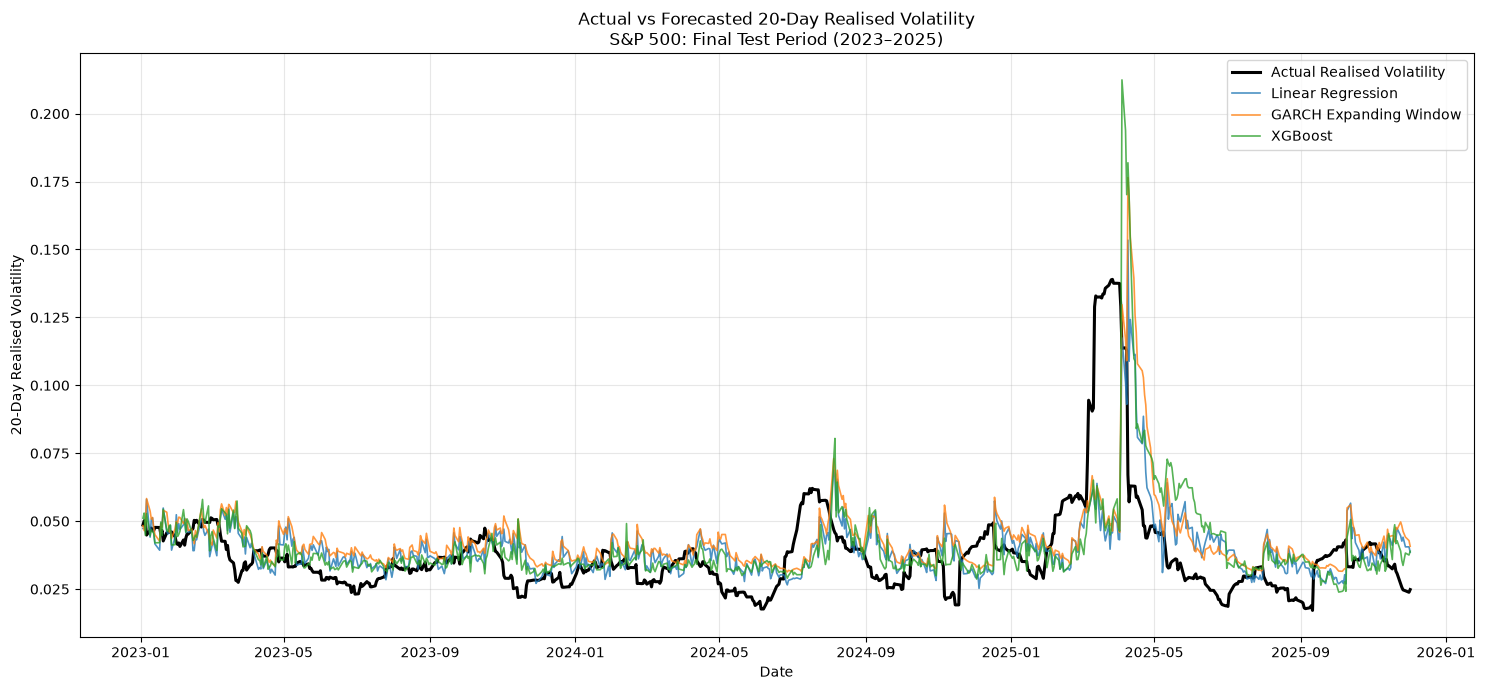

In [29]:
top_models = (
    final_comparison
    .head(3)["Model"]
    .tolist()
)

plt.figure(figsize=(15, 7))

plt.plot(
    final_predictions["Date"],
    final_predictions["Actual"],
    label="Actual Realised Volatility",
    linewidth=2.2,
    color="black"
)

for model_name in top_models:

    plt.plot(
        final_predictions["Date"],
        final_predictions[model_name],
        label=model_name,
        alpha=0.8,
        linewidth=1.2
    )

plt.title(
    "Actual vs Forecasted 20-Day Realised Volatility\n"
    "S&P 500: Final Test Period (2023–2025)"
)

plt.xlabel("Date")
plt.ylabel("20-Day Realised Volatility")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

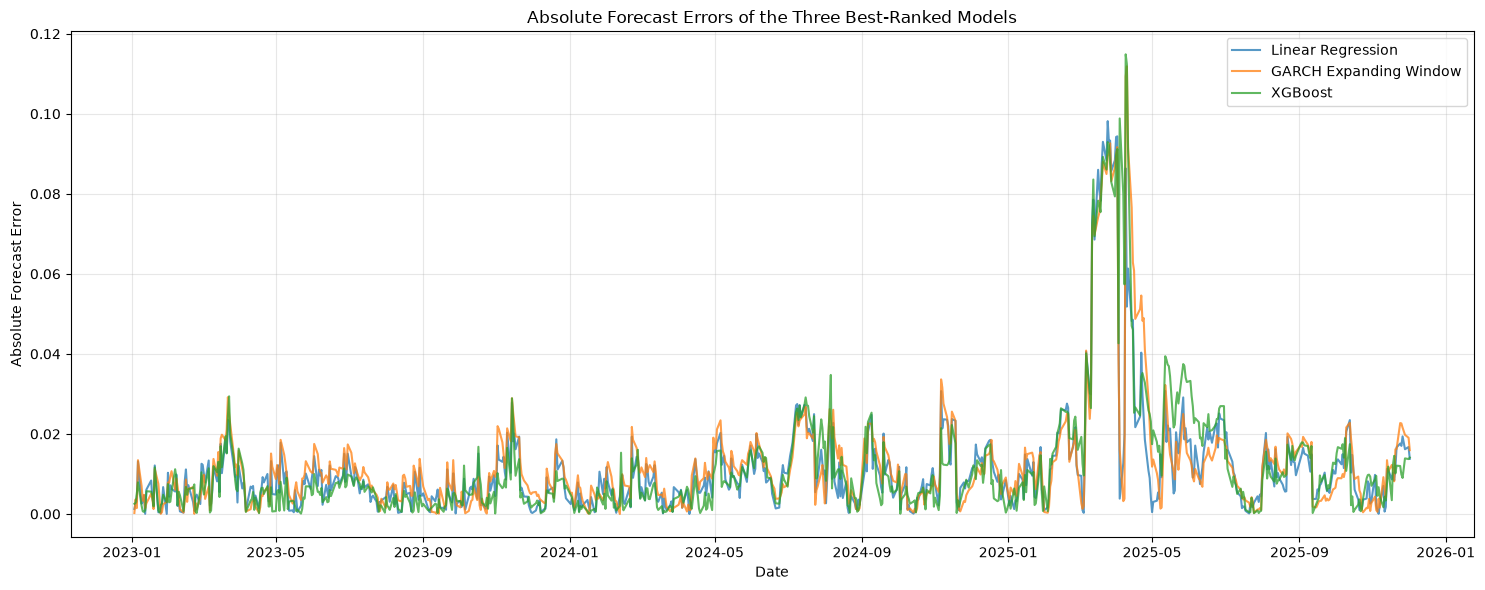

In [30]:
# ============================================================
# FORECASTING ERRORS
# ============================================================

plt.figure(figsize=(15, 6))

for model_name in top_models:

    absolute_errors = np.abs(
        final_predictions["Actual"]
        - final_predictions[model_name]
    )

    plt.plot(
        final_predictions["Date"],
        absolute_errors,
        label=model_name,
        alpha=0.75
    )

plt.title(
    "Absolute Forecast Errors of the Three Best-Ranked Models"
)

plt.xlabel("Date")
plt.ylabel("Absolute Forecast Error")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_test_absolute_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
final_lstm.save(
    MODELS_DIR / "lstm_final_test.keras"
)

pd.DataFrame({
    "Date": test_df["Date"].to_numpy(),
    "Actual": y_test_lstm,
    "LSTM_Predicted": lstm_test_predictions
}).to_csv(
    TABLES_DIR / "final_test_lstm_predictions.csv",
    index=False
)

print("LSTM model and predictions saved successfully!")

LSTM model and predictions saved successfully!
